before running the next cells install the dependencies\
they can be installed globally or though a python environment

```bash
pip install -r requirements.txt
```

In [1]:
pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import geopandas as gpd
import numpy as np
import os

pd.set_option("display.max_columns", None)

In [4]:
individuals_df = pd.read_csv("data/2017/Microdato_Censo2017-personas.csv", sep=";")
individuals_df = individuals_df[individuals_df.COMUNA == 8101]
individuals_df

,REGION,PROVINCIA,COMUNA,DC,AREA,ZC_LOC,ID_ZONA_LOC,NVIV,NHOGAR,PERSONAN,P07,P08,P09,P10,P10COMUNA,P10PAIS,P11,P11COMUNA,P11PAIS,P12,P12COMUNA,P12PAIS,P12A_LLEGADA,P12A_TRAMO,P13,P14,P15,P15A,P16,P16A,P16A_OTRO,P17,P18,P19,P20,P21M,P21A,P10PAIS_GRUPO,P11PAIS_GRUPO,P12PAIS_GRUPO,ESCOLARIDAD,P16A_GRUPO,REGION_15R,PROVINCIA_15R,COMUNA_15R,P10COMUNA_15R,P11COMUNA_15R,P12COMUNA_15R
11593176,8,81,8101,1,1,1,13946,1,1,1,1,1,45,1,98,998,3,8107,998,2,13101,998,9998,98,2,3,11,1,2,98,98,1,M,98,98,98,9998,998,998,998,15,98,8,81,8101,98,8107,13101
11593177,8,81,8101,1,1,1,13946,2,1,1,1,2,47,1,98,998,3,13123,998,2,16101,998,9998,98,2,2,13,1,2,98,98,1,O,0,98,98,9998,998,998,998,19,98,8,81,8101,98,13123,8401
11593178,8,81,8101,1,1,1,13946,3,1,1,1,2,80,1,98,998,2,98,998,2,8311,998,9998,98,2,6,9,1,2,98,98,7,98,3,3,6,1960,998,998,998,12,98,8,81,8101,98,98,8311
11593179,8,81,8101,1,1,1,13946,4,1,1,1,1,54,1,98,998,2,98,998,2,8106,998,9998,98,2,2,11,1,2,98,98,1,Z,98,98,98,9998,998,998,998,14,98,8,81,8101,98,98,8106
11593180,8,81,8101,1,1,1,13946,5,1,1,1,2,48,1,98,998,3,8112,998,2,8110,998,9998,98,2,4,7,1,2,98,98,1,L,3,3,10,1994,998,998,998,12,98,8,81,8101,98,8112,8110
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11816745,8,81,8101,99,1,999,2421,225,1,11,17,1,20,3,8112,998,3,8201,998,2,8201,998,9998,98,1,2,12,2,1,1,98,5,98,98,98,98,9998,998,998,998,14,1,8,81,8101,8112,8201,8201
11816746,8,81,8101,99,1,999,2421,226,1,1,1,2,91,1,98,998,2,98,998,1,98,998,9998,98,2,5,12,1,2,98,98,7,98,4,4,4,1963,998,998,998,17,98,8,81,8101,98,98,98
11816747,8,81,8101,99,1,999,2421,227,1,1,1,1,28,1,98,998,3,997,998,2,8202,998,9998,98,2,2,11,1,2,98,98,1,Z,98,98,98,9998,998,998,998,14,98,8,81,8101,98,997,8202
11816748,8,81,8101,99,1,999,2421,228,1,1,1,1,57,1,98,998,2,98,998,1,98,998,9998,98,2,4,7,1,2,98,98,1,E,98,98,98,9998,998,998,998,12,98,8,81,8101,98,98,98


In [84]:
individuals_df.P08.value_counts()

P08
2    115950
1    107624
Name: count, dtype: int64

In [85]:
individuals = individuals_df.copy()

individuals = individuals.rename(columns={
    "ID_ZONA_LOC": "id_zona",
    "NVIV": "id_vivienda",
    "NHOGAR": "id_hogar",
    "PERSONAN": "id_persona",
    "P08": "sexo",
    "P09": "edad",
    "P12": "lugar_nacimiento",
    "P16": "pertenece_pueblo_indigena",
}, errors="ignore")

individuals = individuals.assign(
    personas = 1,
    hombres = lambda x: x.sexo == 1,
    mujeres = lambda x: x.sexo == 2,
    edad_0a5 = lambda x: x.edad <= 5,
    edad_6a14 = lambda x: x.edad.between(6, 14),
    edad_15a64 = lambda x: x.edad.between(15, 64),
    edad_65ymas = lambda x: x.edad >= 65,
    inmigrantes = lambda x: ~x.lugar_nacimiento.isin([1, 2]),
    pueblo = lambda x: x.pertenece_pueblo_indigena == 1,
)

individuals = individuals[[
    "id_zona",
    "id_vivienda",
    "id_hogar",
    "personas",
    "hombres",
    "mujeres",
    "edad_0a5",
    "edad_6a14",
    "edad_15a64",
    "edad_65ymas",
    "inmigrantes",
    "pueblo",
]]

household_individuals = individuals.groupby(["id_zona", "id_vivienda", "id_hogar"])
household_individuals = household_individuals.sum()
household_individuals = household_individuals.reset_index()

household_individuals

,id_zona,id_vivienda,id_hogar,personas,hombres,mujeres,edad_0a5,edad_6a14,edad_15a64,edad_65ymas,inmigrantes,pueblo
0,522,1,1,1,1,0,0,0,1,0,0,1
1,522,2,1,2,0,2,0,1,1,0,0,0
2,522,3,1,1,0,1,0,0,1,0,0,0
3,522,4,1,4,2,2,0,0,4,0,0,0
4,522,5,1,3,2,1,0,0,3,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
78911,15930,633,1,5,3,2,1,2,2,0,0,0
78912,15930,634,1,1,1,0,0,0,0,1,0,0
78913,15930,635,1,2,1,1,0,0,0,2,0,0
78914,15930,636,1,1,1,0,0,0,0,1,0,0


In [6]:
# folder_path = "data/2017/etiquetas/persona/"

# personas_df = personas.copy()

# for filename in os.listdir(folder_path):
#     # att = filename.split(".")[-2].split("_")[-1].upper()
#     att = filename.split(".")[-2].replace("etiquetas_persona_", "").upper()
#     df = pd.read_csv(os.path.join(folder_path, filename), sep=";")
#     df["display"] = df.apply(lambda row: f"{row.valor}. {row.glosa}", 1)
#     df = df.set_index("valor")
#     try:
#         personas_df[att] = df.loc[personas_df[att], "glosa"].values
#     except:
#         print(f"Error columna {att}")

#     print(f"{att}:\n\t{"\n\t".join(df.display.values.tolist())}\n")

# personas_df

In [7]:
# # lectura de csv comunas para cruce

# comunas = pd.read_csv("data/2017/etiquetas/microdato_censo2017-comunas.csv", sep=";")
# comunas_15r = pd.read_csv("data/2017/etiquetas/microdato_censo2017-comunas_15r.csv", sep=";")

In [16]:
# revision de contenido de los multiple csv de etiquetas
 
folder_path = "data/2017/etiquetas/persona/"
filename = "etiquetas_persona_p12.csv"

pd.read_csv(os.path.join(folder_path, filename), sep=";")

,valor,glosa
0,1,En esta comuna
1,2,En otra comuna
2,3,Perú
3,4,Argentina
4,5,Bolivia
5,6,Ecuador
6,7,Colombia
7,8,Otro
8,98,No aplica
9,99,Missing


In [9]:
households_df = pd.read_csv("data/2017/Microdato_Censo2017-hogares.csv", sep=";")
households_df = households_df[households_df.COMUNA == 8101]
households_df

,REGION,PROVINCIA,COMUNA,DC,AREA,ZC_LOC,ID_ZONA_LOC,NVIV,NHOGAR,TIPO_HOGAR,TIPO_OPERATIVO
3716901,8,81,8101,1,1,1,13946,1,1,1,1
3716902,8,81,8101,1,1,1,13946,2,1,1,1
3716903,8,81,8101,1,1,1,13946,3,1,1,1
3716904,8,81,8101,1,1,1,13946,4,1,1,1
3716905,8,81,8101,1,1,1,13946,5,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...
3795812,8,81,8101,99,1,999,2421,224,1,1,1
3795813,8,81,8101,99,1,999,2421,225,1,98,8
3795814,8,81,8101,99,1,999,2421,226,1,1,1
3795815,8,81,8101,99,1,999,2421,227,1,1,1


In [51]:
households = households_df.copy()

households = households[[
    "ID_ZONA_LOC",
    "NVIV",
    "NHOGAR",
    "TIPO_HOGAR",
    "TIPO_OPERATIVO",
]]

households = households.rename(columns={
    "ID_ZONA_LOC": "id_zona",
    "NVIV": "id_vivienda",
    "NHOGAR": "id_hogar",
    "TIPO_HOGAR": "tipo_hogar",
    "TIPO_OPERATIVO": "tipo_operativo",
}, errors="ignore")

households = households.assign(
    hogares = 1
)

households = households.merge(household_individuals, "left", on=["id_zona", "id_vivienda", "id_hogar"])

households = households.drop(columns=[
    "id_hogar",
    "tipo_hogar",
    "tipo_operativo"
])

houseunits_households = households.groupby(["id_zona", "id_vivienda"])
houseunits_households = houseunits_households.sum()
houseunits_households = houseunits_households.reset_index()

houseunits_households

,id_zona,id_vivienda,hogares,personas,hombres,mujeres,edad_0a5,edad_6a14,edad_15a64,edad_65ymas,inmigrantes,pueblo
0,522,1,1,1,1,0,0,0,1,0,0,1
1,522,2,1,2,0,2,0,1,1,0,0,0
2,522,3,1,1,0,1,0,0,1,0,0,0
3,522,4,1,4,2,2,0,0,4,0,0,0
4,522,5,1,3,2,1,0,0,3,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
75430,15930,633,1,5,3,2,1,2,2,0,0,0
75431,15930,634,1,1,1,0,0,0,0,1,0,0
75432,15930,635,1,2,1,1,0,0,0,2,0,0
75433,15930,636,1,1,1,0,0,0,0,1,0,0


In [11]:
# folder_path = "data/2017/etiquetas/hogar/"

# for filename in os.listdir(folder_path):
#     att = filename.split(".")[-2].split("_")[-1].upper()
#     att = f"TIPO_{att}"
#     df = pd.read_csv(os.path.join(folder_path, filename), sep=";")
#     df["display"] = df.apply(lambda row: f"{row.valor}. {row.glosa}", 1)
#     df = df.set_index("valor")
#     try:
#         hogares[att] = df.loc[hogares[att], "glosa"].values
#     except:
#         pass

#     print(f"{att}:\n\t{"\n\t".join(df.display.values.tolist())}\n")

# hogares

In [12]:
housingunits_df = pd.read_csv("data/2017/Microdato_Censo2017-viviendas.csv", sep=";")
housingunits_df = housingunits_df[housingunits_df.COMUNA == 8101]
housingunits_df

,REGION,PROVINCIA,COMUNA,DC,AREA,ZC_LOC,ID_ZONA_LOC,NVIV,P01,P02,P03A,P03B,P03C,P04,P05,CANT_HOG,CANT_PER,REGION_15R,PROVINCIA_15R,COMUNA_15R
4115678,8,81,8101,1,1,1,13946,1,2,1,1,2,1,1,1,1,1,8,81,8101
4115679,8,81,8101,1,1,1,13946,2,2,1,1,1,1,2,1,1,1,8,81,8101
4115680,8,81,8101,1,1,1,13946,3,2,1,2,2,1,1,1,1,1,8,81,8101
4115681,8,81,8101,1,1,1,13946,4,2,1,1,1,99,3,1,1,1,8,81,8101
4115682,8,81,8101,1,1,1,13946,5,2,1,2,2,1,3,1,1,2,8,81,8101
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4201313,8,81,8101,99,1,999,2421,224,2,1,1,2,1,2,1,1,1,8,81,8101
4201314,8,81,8101,99,1,999,2421,225,8,1,98,98,98,98,98,98,11,8,81,8101
4201315,8,81,8101,99,1,999,2421,226,2,1,1,3,1,2,1,1,1,8,81,8101
4201316,8,81,8101,99,1,999,2421,227,1,1,1,3,2,2,1,1,1,8,81,8101


---
continue here

In [52]:
housingunits = housingunits_df.copy()

housingunits = housingunits[[
    "ID_ZONA_LOC",
    "NVIV",
    "P01",
    "P02",
    "P03A",
    "P03B",
    "P03C",
    "P04",
    "P05",
    "CANT_HOG",
    "CANT_PER",
]]

housingunits = housingunits.rename(columns={
    "ID_ZONA_LOC": "id_zona",
    "NVIV": "id_vivienda",
    "P01": "tipo_vivienda",
    "P02": "tipo_ocupacion",
    "P03A": "material_muros",
    "P03B": "material_techo",
    "P03C": "material_piso",
    "P04": "numero_habitaciones",
    "P05": "origen_agua",
    "CANT_HOG": "numero_hogares",
    "CANT_PER": "numero_personas",
}, errors="ignore")

housingunits = housingunits.assign(
    viviendas = 1,
    viviendas_particulares = lambda x: x.tipo_vivienda <= 7,
    viviendas_colectivas = lambda x: x.tipo_vivienda == 8,
    viviendas_particulares_ocupadas = lambda x: ((x.tipo_vivienda <= 7) & (x.tipo_ocupacion == 1)),
    tipo_vivienda_casa = lambda x: x.tipo_vivienda == 1,
    tipo_vivienda_depto = lambda x: x.tipo_vivienda == 2,
    tipo_vivienda_ruka = lambda x: x.tipo_vivienda == 3,
    tipo_vivienda_pieza = lambda x: x.tipo_vivienda == 4,
    tipo_vivienda_mediagua = lambda x: x.tipo_vivienda == 5,
    tipo_vivienda_movil = lambda x: x.tipo_vivienda == 6,
    tipo_vivienda_otro = lambda x: x.tipo_vivienda == 7,
    material_muros_hormigon = lambda x: x.material_muros == 1,
    material_muros_ladrillo = lambda x: x.material_muros == 2,
    material_muros_forrado = lambda x: x.material_muros == 3,
    material_muros_tabique = lambda x: x.material_muros == 4,
    material_muros_adobe = lambda x: x.material_muros == 5,
    material_muros_precario = lambda x: x.material_muros == 6,
    material_techo_tejas = lambda x: x.material_techo == 1,
    material_techo_losa = lambda x: x.material_techo == 2,
    material_techo_zinc = lambda x: x.material_techo == 3,
    material_techo_fonolita = lambda x: x.material_techo == 4,
    material_techo_paja = lambda x: x.material_techo == 5,
    material_techo_precario = lambda x: x.material_techo == 6,
    material_techo_descubierto = lambda x: x.material_techo == 7,
    material_piso_parquet = lambda x: x.material_piso == 1,
    material_piso_radier = lambda x: x.material_piso == 2,
    material_piso_baldosa = lambda x: x.material_piso == 3,
    material_piso_cemento = lambda x: x.material_piso == 4,
    material_piso_tierra = lambda x: x.material_piso == 5,
    origen_agua_publica = lambda x: x.origen_agua == 1,
    origen_agua_pozo = lambda x: x.origen_agua == 2,
    origen_agua_aljibe = lambda x: x.origen_agua == 3,
    origen_agua_natural = lambda x: x.origen_agua == 4,
)

housingunits = housingunits.merge(houseunits_households, "left", on=["id_zona", "id_vivienda"])

housingunits = housingunits.drop(columns=[
    "id_vivienda",
    "tipo_vivienda",
    "tipo_ocupacion",
    "material_muros",
    "material_techo",
    "material_piso",
    "numero_habitaciones",
    "origen_agua",
    "numero_hogares",
    "numero_personas",
])

zone_housingunits = housingunits.groupby(["id_zona"])
zone_housingunits = zone_housingunits.sum()
zone_housingunits = zone_housingunits.reset_index()

zone_housingunits

,id_zona,viviendas,viviendas_particulares,viviendas_colectivas,viviendas_particulares_ocupadas,tipo_vivienda_casa,tipo_vivienda_depto,tipo_vivienda_ruka,tipo_vivienda_pieza,tipo_vivienda_mediagua,tipo_vivienda_movil,tipo_vivienda_otro,material_muros_hormigon,material_muros_ladrillo,material_muros_forrado,material_muros_tabique,material_muros_adobe,material_muros_precario,material_techo_tejas,material_techo_losa,material_techo_zinc,material_techo_fonolita,material_techo_paja,material_techo_precario,material_techo_descubierto,material_piso_parquet,material_piso_radier,material_piso_baldosa,material_piso_cemento,material_piso_tierra,origen_agua_publica,origen_agua_pozo,origen_agua_aljibe,origen_agua_natural,hogares,personas,hombres,mujeres,edad_0a5,edad_6a14,edad_15a64,edad_65ymas,inmigrantes,pueblo
0,522,859,858,1,804,404,448,0,3,2,0,1,393,283,108,18,0,2,79,124,594,0,0,2,0,779,7,13,2,0,801,0,0,0,817.0,2383.0,1101.0,1282.0,141.0,229.0,1652.0,361.0,57.0,230.0
1,565,31,31,0,30,31,0,0,0,0,0,0,1,5,20,4,0,0,2,0,28,0,0,0,0,30,0,0,0,0,19,7,0,4,30.0,100.0,49.0,51.0,10.0,15.0,62.0,13.0,4.0,21.0
2,592,827,826,1,780,682,135,0,4,3,0,2,147,238,281,97,0,12,49,54,663,1,0,7,1,719,15,30,14,0,775,0,0,0,809.0,2355.0,1101.0,1254.0,134.0,239.0,1609.0,373.0,44.0,255.0
3,793,1162,1162,0,1092,1029,89,0,15,26,0,3,168,565,251,96,0,11,57,2,1017,4,0,9,0,930,17,128,14,0,1085,1,1,0,1120.0,3640.0,1763.0,1877.0,283.0,446.0,2555.0,356.0,75.0,393.0
4,836,1562,1552,10,1215,231,1318,0,0,0,0,3,966,216,25,5,0,0,197,672,336,2,0,0,0,1207,2,1,0,0,1210,0,0,0,1401.0,2688.0,1201.0,1487.0,75.0,86.0,2186.0,341.0,160.0,192.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,14856,1479,1477,2,1096,502,927,0,15,27,0,6,599,78,307,95,0,11,84,429,555,0,0,21,0,1011,21,30,22,0,1071,1,17,0,1123.0,2727.0,1333.0,1394.0,196.0,275.0,2044.0,212.0,134.0,258.0
99,15214,1217,1217,0,1133,1215,0,0,0,0,0,2,650,459,19,3,0,0,820,13,297,1,0,0,0,1114,3,13,1,0,1130,0,0,0,1137.0,3886.0,1863.0,2023.0,408.0,671.0,2625.0,182.0,77.0,174.0
100,15267,1179,1179,0,1111,1177,1,0,0,1,0,0,639,452,18,0,0,1,554,6,543,0,0,2,0,1050,10,41,4,0,1104,1,0,0,1127.0,3814.0,1807.0,2007.0,394.0,504.0,2696.0,220.0,121.0,289.0
101,15370,783,783,0,704,744,0,0,4,34,0,1,113,360,162,55,2,9,57,0,626,1,0,19,0,527,9,150,13,0,698,0,0,1,708.0,2320.0,1124.0,1196.0,178.0,291.0,1537.0,314.0,19.0,256.0


In [ ]:
# folder_path = "data/2017/etiquetas/vivienda/"

# for filename in os.listdir(folder_path):
#     att = filename.split(".")[-2].split("_")[-1].upper()
#     df = pd.read_csv(os.path.join(folder_path, filename), sep=";")
#     df["display"] = df.apply(lambda row: f"{row.valor}. {row.glosa}", 1)
#     df = df.set_index("valor")
#     try:
#         viviendas[att] = df.loc[viviendas[att], "glosa"].values
#     except:
#         pass

#     print(f"{att}:\n\t{"\n\t".join(df.display.values.tolist())}\n")

# viviendas

In [97]:
geoms = gpd.read_file("data/2017/microdatos_manzana/Microdatos_Manzana.shp", encoding="latin1")

for c in ["REGION", "PROVINCIA", "COMUNA", "NOMBRE_DIS"]:
    geoms[c] = (
        geoms[c]
        .astype(str)
        .str.encode("latin1", errors="ignore")
        .str.decode("utf-8", errors="ignore")
    )

for c in geoms.columns:
    geoms = geoms.rename(columns={c: c.lower()}, errors="ignore")

geoms = geoms[geoms.comuna == "CONCEPCIÓN"]
geoms = geoms.to_crs(4326)
geoms.manzent = geoms.manzent.astype(int)
geoms = geoms.rename(columns={"manzent": "id_manzent"})
geoms = geoms.replace("Indeterminado", np.nan)
geoms

,cut,region,provincia,comuna,nombre_dis,codigo_dis,id_manzent,zona_censa,manzana,total_pers,total_homb,total_muje,personas_0,personas_6,personas_1,personas_m,personas_e,pueblos_in,total_viv_,total_viv1,viv_ocupa_,total_vivi,cantidad_h,viv_tipo_c,viv_tipo_d,viv_tipo_t,viv_tipo_p,viv_tipo_m,viv_tipo_1,viv_tipo_o,viv_pared_,viv_pared1,viv_pare_1,viv_pare_2,viv_pare_3,viv_pare_4,viv_techo_,viv_techo1,viv_tech_1,viv_tech_2,viv_tech_3,viv_tech_4,viv_tech_5,viv_piso_p,viv_piso_r,viv_piso_b,viv_piso_c,viv_piso_t,viv_materi,viv_mate_1,viv_mate_2,viv_agua_r,viv_agua_p,viv_agua_c,viv_agua_1,geometry
138477,8101,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,PEDRO DE VALDIVIA,26,8101261003001,3,1,67,36,31,7,11,44,5,0,12,20,0,20,20,20,20,0,0,0,0,0,0,0,2,14,1,0,3,1,0,17,0,0,2,0,18,0,2,0,0,13,3,4,20,0,0,0,"POLYGON ((-73.06065 -36.83835, -73.06067 -36.8..."
138478,8101,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,PEDRO DE VALDIVIA,26,8101261003005,3,5,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,"POLYGON ((-73.05748 -36.83809, -73.05799 -36.8..."
138479,8101,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,PEDRO DE VALDIVIA,26,8101261002006,2,6,53,22,31,NaN,NaN,38,8,NaN,5,22,0,19,22,19,22,0,0,0,0,0,0,2,2,7,8,0,0,1,0,17,0,0,0,0,11,0,7,1,0,8,10,0,19,0,0,0,"POLYGON ((-73.05655 -36.83784, -73.05734 -36.8..."
138480,8101,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,LO PEQUÉN,32,8101321004027,4,27,131,66,65,13,20,83,15,0,8,41,0,39,41,41,39,0,0,0,2,0,0,0,3,32,0,2,2,0,0,37,0,0,2,0,37,1,0,1,0,31,4,4,39,0,0,0,"POLYGON ((-73.00417 -36.83844, -73.00419 -36.8..."
138481,8101,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,LA TOMA,16,8101161003010,3,10,410,185,225,17,46,296,51,0,26,135,0,128,135,135,135,0,0,0,0,0,0,9,99,15,5,0,0,20,0,108,0,0,0,0,116,1,10,0,0,111,16,0,128,0,0,0,"POLYGON ((-73.04733 -36.79638, -73.04652 -36.7..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
140472,8101,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,LA PÓLVORA,17,8101171002023,2,23,34,11,23,NaN,NaN,24,7,0,NaN,11,0,10,11,10,8,0,0,0,1,0,2,1,1,6,0,0,2,2,0,8,0,0,0,0,10,0,0,0,0,8,0,2,10,0,0,0,"POLYGON ((-73.0377 -36.80896, -73.03775 -36.80..."
140473,8101,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,ANDALIÉN,18,8101181001025,1,25,56,25,31,NaN,NaN,43,7,0,10,19,0,18,19,19,19,0,0,0,0,0,0,14,3,1,0,0,0,3,0,15,0,0,0,0,2,0,16,0,0,2,16,0,18,0,0,0,"POLYGON ((-73.02926 -36.80891, -73.02928 -36.8..."
140474,8101,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,PAJONAL,10,8101101004017,4,17,45,22,23,NaN,NaN,30,10,0,0,15,0,13,15,13,14,0,0,0,1,0,0,12,0,1,0,0,0,0,0,13,0,0,0,0,13,0,0,0,0,13,0,0,13,0,0,0,"POLYGON ((-73.05297 -36.80926, -73.0533 -36.80..."
140475,8101,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,ANDALIÉN,18,8101181001019,1,19,30,14,16,0,NaN,22,NaN,0,5,11,0,11,11,11,11,0,0,0,0,0,0,1,4,4,1,0,1,0,0,11,0,0,0,0,11,0,0,0,0,9,1,1,11,0,0,0,"POLYGON ((-73.02699 -36.80883, -73.027 -36.808..."


In [98]:
geoms[geoms.id_manzent == 8101011001014]

,cut,region,provincia,comuna,nombre_dis,codigo_dis,id_manzent,zona_censa,manzana,total_pers,total_homb,total_muje,personas_0,personas_6,personas_1,personas_m,personas_e,pueblos_in,total_viv_,total_viv1,viv_ocupa_,total_vivi,cantidad_h,viv_tipo_c,viv_tipo_d,viv_tipo_t,viv_tipo_p,viv_tipo_m,viv_tipo_1,viv_tipo_o,viv_pared_,viv_pared1,viv_pare_1,viv_pare_2,viv_pare_3,viv_pare_4,viv_techo_,viv_techo1,viv_tech_1,viv_tech_2,viv_tech_3,viv_tech_4,viv_tech_5,viv_piso_p,viv_piso_r,viv_piso_b,viv_piso_c,viv_piso_t,viv_materi,viv_mate_1,viv_mate_2,viv_agua_r,viv_agua_p,viv_agua_c,viv_agua_1,geometry
139446,8101,REGIÓN DEL BIOBÍO,CONCEPCIÓN,CONCEPCIÓN,INTENDENCIA,1,8101011001014,1,14,104,46,58,NaN,NaN,74,23,4,10,56,1,44,57,52,0,54,0,0,0,0,2,39,5,0,0,0,0,4,33,7,0,0,0,0,44,0,0,0,0,44,0,0,44,0,0,0,"POLYGON ((-73.04729 -36.8254, -73.04678 -36.82..."


In [119]:
manzanas = pd.read_csv("data/2017/Microdato_Censo2017-Manzanas.csv", sep=";")
manzanas = manzanas[manzanas.COMUNA == 8101]
manzanas.ID_MANZENT = manzanas.ID_MANZENT.astype(int)

manzanas = manzanas.rename(columns={
    "ID_ZONA_LOC": "id_zona",
    "HOMBRES": "hombres",
    "MUJERES": "mujeres",
    "INMIGRANTES": "inmigrantes",
    "VIV_PART": "viviendas_particulares",
    "VIV_COL": "viviendas_colectivas",
    "VPOMP": "viviendas_particulares_ocupadas",
    "TOTAL_VIV": "viviendas",
    "CANT_HOG": "hogares",
    "P01_1": "tipo_vivienda_casa",
    "P01_2": "tipo_vivienda_depto",
    "P01_3": "tipo_vivienda_ruka",
    "P01_4": "tipo_vivienda_pieza",
    "P01_5": "tipo_vivienda_mediagua",
    "P01_6": "tipo_vivienda_movil",
    "P01_7": "tipo_vivienda_otro",
    "P03A_1": "material_muros_hormigon",
    "P03A_2": "material_muros_ladrillo",
    "P03A_3": "material_muros_forrado",
    "P03A_4": "material_muros_tabique",
    "P03A_5": "material_muros_adobe",
    "P03A_6": "material_muros_precario",
    "P03B_1": "material_techo_tejas",
    "P03B_2": "material_techo_losa",
    "P03B_3": "material_techo_zinc",
    "P03B_4": "material_techo_fonolita",
    "P03B_5": "material_techo_paja",
    "P03B_6": "material_techo_precario",
    "P03B_7": "material_techo_descubierto",
    "P03C_1": "material_piso_parquet",
    "P03C_2": "material_piso_radier",
    "P03C_3": "material_piso_baldosa",
    "P03C_4": "material_piso_cemento",
    "P03C_5": "material_piso_tierra",
    "P05_1": "origen_agua_publica",
    "P05_2": "origen_agua_pozo",
    "P05_3": "origen_agua_aljibe",
    "P05_4": "origen_agua_natural",
}, errors="ignore")

manzanas = manzanas.rename(columns={c: c.lower() for c in manzanas.columns}, errors="ignore")
manzanas = manzanas.drop(columns=[c for c in manzanas.columns if "15r" in c], errors="ignore")

value_columns = [
    "personas",
    "hombres",
    "mujeres",
    "edad_0a5",
    "edad_6a14",
    "edad_15a64",
    "edad_65ymas",
    "inmigrantes",
    "pueblo",
    "viviendas_particulares",
    "viviendas_colectivas",
    "viviendas_particulares_ocupadas",
    "viviendas",
    "hogares",
    "tipo_vivienda_casa",
    "tipo_vivienda_depto",
    "tipo_vivienda_ruka",
    "tipo_vivienda_pieza",
    "tipo_vivienda_mediagua",
    "tipo_vivienda_movil",
    "tipo_vivienda_otro",
    "material_muros_hormigon",
    "material_muros_ladrillo",
    "material_muros_forrado",
    "material_muros_tabique",
    "material_muros_adobe",
    "material_muros_precario",
    "material_techo_tejas",
    "material_techo_losa",
    "material_techo_zinc",
    "material_techo_fonolita",
    "material_techo_paja",
    "material_techo_precario",
    "material_techo_descubierto",
    "material_piso_parquet",
    "material_piso_radier",
    "material_piso_baldosa",
    "material_piso_cemento",
    "material_piso_tierra",
    "matacep",
    "matrec",
    "matirrec",
    "origen_agua_publica",
    "origen_agua_pozo",
    "origen_agua_aljibe",
    "origen_agua_natural"
]

manzanas = manzanas.replace("*", "NaN")
for c in value_columns:
    manzanas[c] = manzanas[c].astype(float)

manzanas

,region,provincia,comuna,dc,area,zc_loc,mz_ent,id_zona,id_manzent,personas,hombres,mujeres,edad_0a5,edad_6a14,edad_15a64,edad_65ymas,inmigrantes,pueblo,viviendas_particulares,viviendas_colectivas,viviendas_particulares_ocupadas,viviendas,hogares,tipo_vivienda_casa,tipo_vivienda_depto,tipo_vivienda_ruka,tipo_vivienda_pieza,tipo_vivienda_mediagua,tipo_vivienda_movil,tipo_vivienda_otro,material_muros_hormigon,material_muros_ladrillo,material_muros_forrado,material_muros_tabique,material_muros_adobe,material_muros_precario,material_techo_tejas,material_techo_losa,material_techo_zinc,material_techo_fonolita,material_techo_paja,material_techo_precario,material_techo_descubierto,material_piso_parquet,material_piso_radier,material_piso_baldosa,material_piso_cemento,material_piso_tierra,matacep,matrec,matirrec,origen_agua_publica,origen_agua_pozo,origen_agua_aljibe,origen_agua_natural
68804,8,81,8101,1,1,1,14,13946,8101011001014,104.0,46.0,58.0,NaN,NaN,74.0,23.0,4.0,10.0,56.0,1.0,44.0,57.0,52.0,0.0,54.0,0.0,0.0,0.0,0.0,2.0,39.0,5.0,0.0,0.0,0.0,0.0,4.0,33.0,7.0,0.0,0.0,0.0,0.0,44.0,0.0,0.0,0.0,0.0,44.0,0.0,0.0,44.0,0.0,0.0,0.0
68805,8,81,8101,1,1,1,15,13946,8101011001015,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
68806,8,81,8101,1,1,1,16,13946,8101011001016,104.0,45.0,59.0,8.0,7.0,67.0,22.0,NaN,8.0,51.0,0.0,43.0,51.0,44.0,2.0,49.0,0.0,0.0,0.0,0.0,0.0,35.0,8.0,0.0,0.0,0.0,0.0,17.0,18.0,7.0,0.0,0.0,0.0,0.0,42.0,0.0,0.0,0.0,0.0,42.0,0.0,0.0,42.0,0.0,0.0,0.0
68807,8,81,8101,1,1,1,17,13946,8101011001017,91.0,44.0,47.0,NaN,NaN,67.0,18.0,5.0,NaN,47.0,1.0,34.0,48.0,41.0,1.0,46.0,0.0,0.0,0.0,0.0,0.0,25.0,8.0,1.0,0.0,0.0,0.0,0.0,6.0,28.0,0.0,0.0,0.0,0.0,34.0,0.0,0.0,0.0,0.0,34.0,0.0,0.0,34.0,0.0,0.0,0.0
68808,8,81,8101,1,1,1,18,13946,8101011001018,70.0,34.0,36.0,0.0,NaN,56.0,NaN,NaN,NaN,40.0,0.0,39.0,40.0,39.0,1.0,39.0,0.0,0.0,0.0,0.0,0.0,23.0,16.0,0.0,0.0,0.0,0.0,0.0,36.0,3.0,0.0,0.0,0.0,0.0,39.0,0.0,0.0,0.0,0.0,39.0,0.0,0.0,39.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70468,8,81,8101,9,1,1,7,11000,8101091001007,47.0,25.0,22.0,NaN,NaN,25.0,15.0,0.0,5.0,17.0,0.0,15.0,17.0,16.0,17.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0,0.0,0.0,0.0,0.0,7.0,0.0,8.0,0.0,0.0,0.0,0.0,15.0,0.0,0.0,0.0,0.0,15.0,0.0,0.0,15.0,0.0,0.0,0.0
70469,8,81,8101,9,1,1,8,11000,8101091001008,11.0,6.0,5.0,0.0,0.0,NaN,NaN,0.0,0.0,6.0,0.0,6.0,6.0,6.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,2.0,2.0,0.0,0.0,0.0,2.0,0.0,4.0,0.0,0.0,0.0,0.0,3.0,0.0,3.0,0.0,0.0,3.0,3.0,0.0,6.0,0.0,0.0,0.0
70470,8,81,8101,9,1,1,9,11000,8101091001009,27.0,11.0,16.0,NaN,NaN,16.0,8.0,0.0,NaN,17.0,0.0,10.0,17.0,10.0,17.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0,0.0,0.0,0.0,5.0,0.0,5.0,0.0,0.0,0.0,0.0,8.0,0.0,2.0,0.0,0.0,8.0,2.0,0.0,10.0,0.0,0.0,0.0
70471,8,81,8101,9,1,1,901,11000,8101091001901,72.0,36.0,36.0,NaN,NaN,43.0,20.0,0.0,22.0,23.0,0.0,23.0,23.0,23.0,23.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,18.0,0.0,1.0,0.0,0.0,15.0,0.0,8.0,0.0,0.0,0.0,0.0,23.0,0.0,0.0,0.0,0.0,22.0,1.0,0.0,23.0,0.0,0.0,0.0


In [169]:
manzanas[manzanas.edad_0a5 == 4.0]

,region,provincia,comuna,dc,area,zc_loc,mz_ent,id_zona,id_manzent,personas,hombres,mujeres,edad_0a5,edad_6a14,edad_15a64,edad_65ymas,inmigrantes,pueblo,viviendas_particulares,viviendas_colectivas,viviendas_particulares_ocupadas,viviendas,hogares,tipo_vivienda_casa,tipo_vivienda_depto,tipo_vivienda_ruka,tipo_vivienda_pieza,tipo_vivienda_mediagua,tipo_vivienda_movil,tipo_vivienda_otro,material_muros_hormigon,material_muros_ladrillo,material_muros_forrado,material_muros_tabique,material_muros_adobe,material_muros_precario,material_techo_tejas,material_techo_losa,material_techo_zinc,material_techo_fonolita,material_techo_paja,material_techo_precario,material_techo_descubierto,material_piso_parquet,material_piso_radier,material_piso_baldosa,material_piso_cemento,material_piso_tierra,matacep,matrec,matirrec,origen_agua_publica,origen_agua_pozo,origen_agua_aljibe,origen_agua_natural
68809,8,81,8101,1,1,1,19,13946,8101011001019,198.0,96.0,102.0,4.0,13.0,132.0,49.0,5.0,7.0,93.0,0.0,81.0,93.0,89.0,3.0,90.0,0.0,0.0,0.0,0.0,0.0,58.0,22.0,0.0,0.0,0.0,0.0,23.0,54.0,4.0,0.0,0.0,0.0,0.0,81.0,0.0,0.0,0.0,0.0,80.0,0.0,0.0,80.0,0.0,0.0,0.0
68821,8,81,8101,10,1,1,13,6126,8101101001013,74.0,37.0,37.0,4.0,5.0,56.0,9.0,0.0,4.0,21.0,0.0,18.0,21.0,18.0,21.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,16.0,1.0,0.0,0.0,0.0,1.0,0.0,17.0,0.0,0.0,0.0,0.0,16.0,0.0,2.0,0.0,0.0,16.0,2.0,0.0,18.0,0.0,0.0,0.0
68822,8,81,8101,10,1,1,14,6126,8101101001014,101.0,55.0,46.0,4.0,6.0,76.0,15.0,0.0,4.0,29.0,0.0,29.0,29.0,32.0,29.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,21.0,3.0,1.0,0.0,0.0,2.0,0.0,27.0,0.0,0.0,0.0,0.0,29.0,0.0,0.0,0.0,0.0,28.0,1.0,0.0,29.0,0.0,0.0,0.0
68829,8,81,8101,10,1,1,21,6126,8101101001021,52.0,20.0,32.0,4.0,4.0,34.0,10.0,0.0,NaN,15.0,0.0,15.0,15.0,15.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,9.0,3.0,0.0,0.0,0.0,2.0,0.0,13.0,0.0,0.0,0.0,0.0,13.0,0.0,1.0,1.0,0.0,13.0,2.0,0.0,15.0,0.0,0.0,0.0
68860,8,81,8101,10,1,3,19,6057,8101101003019,36.0,19.0,17.0,4.0,5.0,22.0,5.0,0.0,5.0,12.0,0.0,12.0,12.0,12.0,12.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,10.0,0.0,0.0,0.0,0.0,2.0,0.0,10.0,0.0,0.0,0.0,0.0,12.0,0.0,0.0,0.0,0.0,12.0,0.0,0.0,12.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70408,8,81,8101,8,1,5,13,8081,8101081005013,62.0,29.0,33.0,4.0,11.0,40.0,7.0,0.0,NaN,15.0,0.0,15.0,15.0,18.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,7.0,3.0,0.0,0.0,0.0,0.0,15.0,0.0,0.0,0.0,0.0,15.0,0.0,0.0,0.0,0.0,12.0,3.0,0.0,15.0,0.0,0.0,0.0
70424,8,81,8101,8,1,5,29,8081,8101081005029,65.0,34.0,31.0,4.0,5.0,42.0,14.0,0.0,5.0,21.0,0.0,19.0,21.0,21.0,21.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,14.0,2.0,2.0,0.0,0.0,1.0,0.0,18.0,0.0,0.0,0.0,0.0,18.0,1.0,0.0,0.0,0.0,16.0,3.0,0.0,19.0,0.0,0.0,0.0
70427,8,81,8101,8,1,5,31,8081,8101081005031,81.0,37.0,44.0,4.0,7.0,63.0,7.0,0.0,12.0,29.0,0.0,29.0,29.0,30.0,29.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,28.0,1.0,0.0,0.0,0.0,0.0,0.0,29.0,0.0,0.0,0.0,0.0,27.0,0.0,0.0,2.0,0.0,27.0,2.0,0.0,29.0,0.0,0.0,0.0
70437,8,81,8101,9,1,1,13,11000,8101091001013,71.0,34.0,37.0,4.0,4.0,44.0,19.0,NaN,NaN,18.0,0.0,18.0,18.0,18.0,18.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,16.0,0.0,1.0,0.0,0.0,8.0,0.0,9.0,0.0,0.0,0.0,0.0,18.0,0.0,0.0,0.0,0.0,16.0,1.0,0.0,16.0,0.0,0.0,0.0


In [145]:
manzanas[["id_zona", "id_manzent"]]

,id_zona,id_manzent
68804,13946,8101011001014
68805,13946,8101011001015
68806,13946,8101011001016
68807,13946,8101011001017
68808,13946,8101011001018
...,...,...
70468,11000,8101091001007
70469,11000,8101091001008
70470,11000,8101091001009
70471,11000,8101091001901


In [120]:
blocks = manzanas.merge(geoms[["id_manzent", "geometry"]], "left", "id_manzent")
blocks = gpd.GeoDataFrame(blocks, geometry="geometry", crs=4326)
print(len(blocks))
blocks.head()

1669


,region,provincia,comuna,dc,area,zc_loc,mz_ent,id_zona,id_manzent,personas,hombres,mujeres,edad_0a5,edad_6a14,edad_15a64,edad_65ymas,inmigrantes,pueblo,viviendas_particulares,viviendas_colectivas,viviendas_particulares_ocupadas,viviendas,hogares,tipo_vivienda_casa,tipo_vivienda_depto,tipo_vivienda_ruka,tipo_vivienda_pieza,tipo_vivienda_mediagua,tipo_vivienda_movil,tipo_vivienda_otro,material_muros_hormigon,material_muros_ladrillo,material_muros_forrado,material_muros_tabique,material_muros_adobe,material_muros_precario,material_techo_tejas,material_techo_losa,material_techo_zinc,material_techo_fonolita,material_techo_paja,material_techo_precario,material_techo_descubierto,material_piso_parquet,material_piso_radier,material_piso_baldosa,material_piso_cemento,material_piso_tierra,matacep,matrec,matirrec,origen_agua_publica,origen_agua_pozo,origen_agua_aljibe,origen_agua_natural,geometry
0,8,81,8101,1,1,1,14,13946,8101011001014,104.0,46.0,58.0,NaN,NaN,74.0,23.0,4.0,10.0,56.0,1.0,44.0,57.0,52.0,0.0,54.0,0.0,0.0,0.0,0.0,2.0,39.0,5.0,0.0,0.0,0.0,0.0,4.0,33.0,7.0,0.0,0.0,0.0,0.0,44.0,0.0,0.0,0.0,0.0,44.0,0.0,0.0,44.0,0.0,0.0,0.0,"POLYGON ((-73.04729 -36.8254, -73.04678 -36.82..."
1,8,81,8101,1,1,1,15,13946,8101011001015,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"POLYGON ((-73.04599 -36.82508, -73.04572 -36.8..."
2,8,81,8101,1,1,1,16,13946,8101011001016,104.0,45.0,59.0,8.0,7.0,67.0,22.0,NaN,8.0,51.0,0.0,43.0,51.0,44.0,2.0,49.0,0.0,0.0,0.0,0.0,0.0,35.0,8.0,0.0,0.0,0.0,0.0,17.0,18.0,7.0,0.0,0.0,0.0,0.0,42.0,0.0,0.0,0.0,0.0,42.0,0.0,0.0,42.0,0.0,0.0,0.0,"POLYGON ((-73.046 -36.82722, -73.04604 -36.827..."
3,8,81,8101,1,1,1,17,13946,8101011001017,91.0,44.0,47.0,NaN,NaN,67.0,18.0,5.0,NaN,47.0,1.0,34.0,48.0,41.0,1.0,46.0,0.0,0.0,0.0,0.0,0.0,25.0,8.0,1.0,0.0,0.0,0.0,0.0,6.0,28.0,0.0,0.0,0.0,0.0,34.0,0.0,0.0,0.0,0.0,34.0,0.0,0.0,34.0,0.0,0.0,0.0,"POLYGON ((-73.04705 -36.82681, -73.04702 -36.8..."
4,8,81,8101,1,1,1,18,13946,8101011001018,70.0,34.0,36.0,0.0,NaN,56.0,NaN,NaN,NaN,40.0,0.0,39.0,40.0,39.0,1.0,39.0,0.0,0.0,0.0,0.0,0.0,23.0,16.0,0.0,0.0,0.0,0.0,0.0,36.0,3.0,0.0,0.0,0.0,0.0,39.0,0.0,0.0,0.0,0.0,39.0,0.0,0.0,39.0,0.0,0.0,0.0,"POLYGON ((-73.04847 -36.82824, -73.04852 -36.8..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

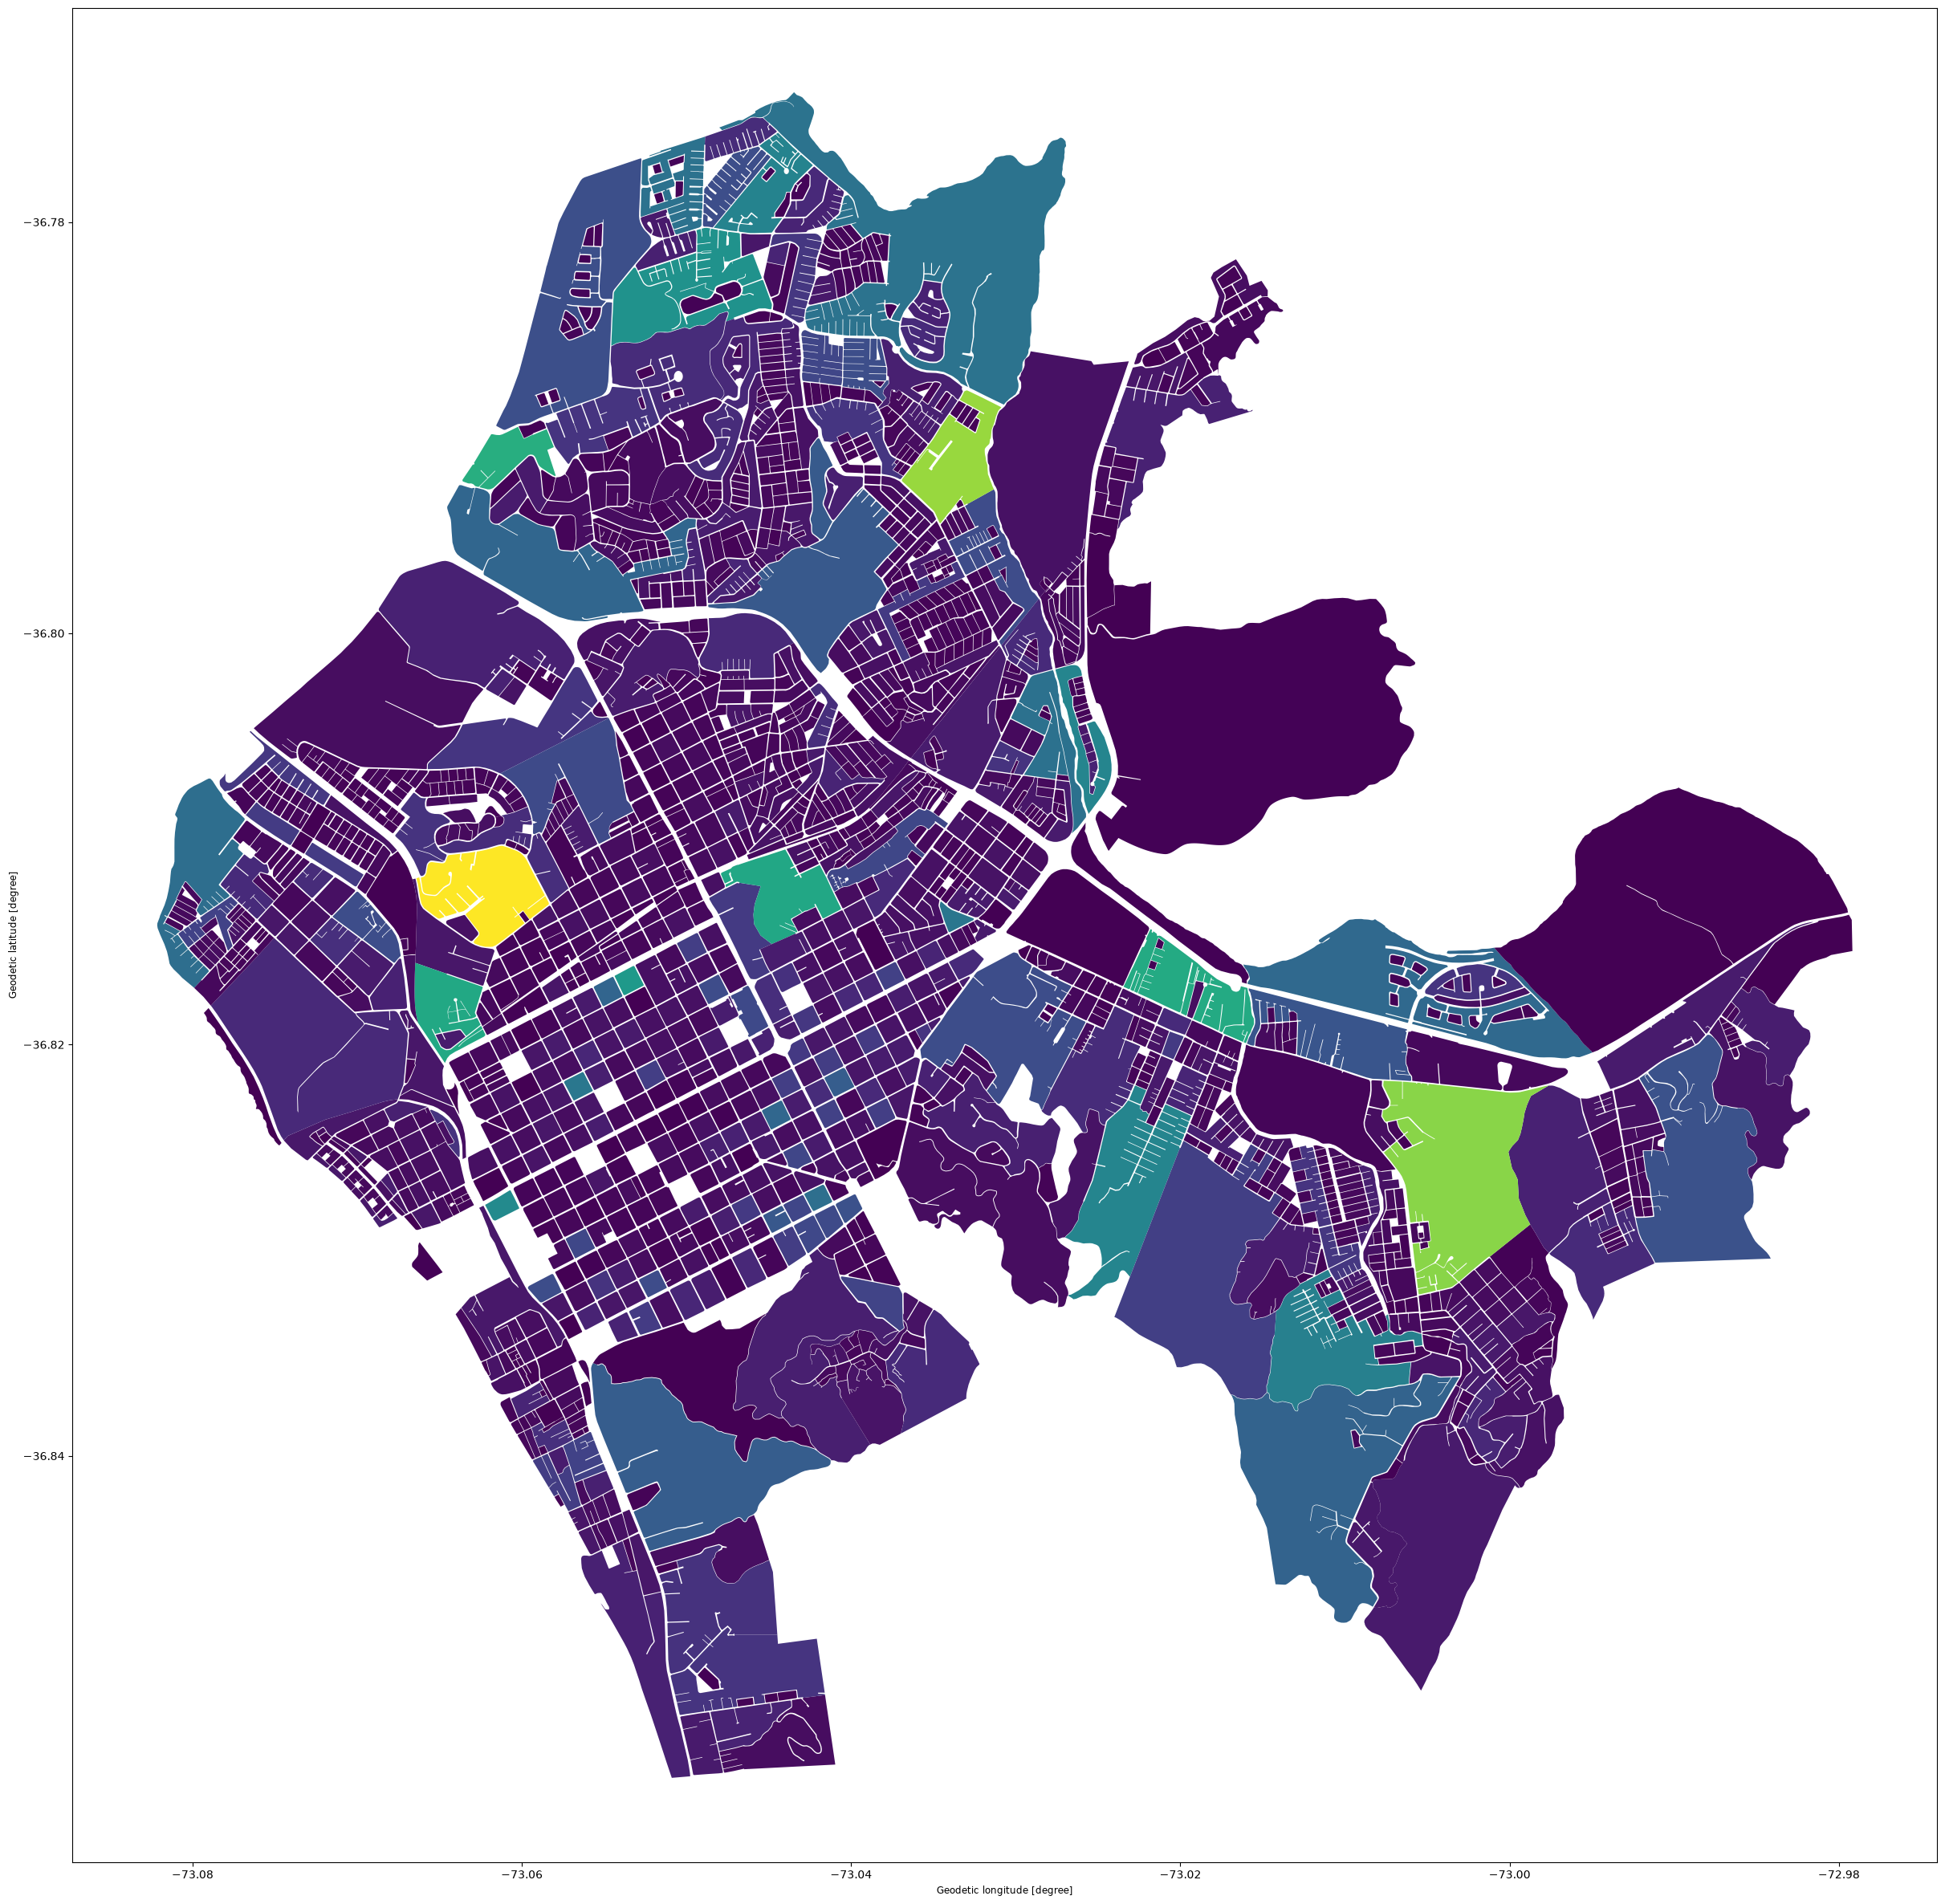

In [135]:
blocks.plot(figsize=(30,30), column="viviendas")

---

In [ ]:
import numpy as np

# household_features: 2d array of shape (n_households, n_attrs) from base de hogares
# household_features = 

# # block_capacities: 1d array of shape (n_blocks,) from base de manzanas total dwellings
# block_capacities = 

# # block_targets: 2d array of shape (n_blocks, n_attrs) from base de manzanas aggregated counts
# block_targets =

# # boolean array (n_blocks, n_attrs)
# target_is_censored =

In [ ]:
from scipy.optimize import milp, LinearConstraint
from scipy.sparse import csc_matrix
    
n_households = household_features.shape[0]
n_blocks = len(block_capacities)
n_attrs = block_targets.shape[1]

n_x = n_households * n_blocks
n_slacks = 2 * n_blocks * n_attrs
n_vars = n_x + n_slacks

lb = np.zeros(n_vars)
ub = np.ones(n_vars)  # binary assignment x_ij are 0 or 1
ub[n_x:] = np.inf     # slacks can be any positive number

integrality = np.zeros(n_vars, dtype=int)
integrality[:n_x] = 1 # assignment variables are binary integers

# minimize slack penalties
c = np.zeros(n_vars)
m_penalty = 1000.0
c[n_x:] = m_penalty

rows_A = []
cols_A = []
data_A = []
lb_A = []
ub_A = []

current_row = 0

# constraint 1: every household must be assigned to exactly one block
for i in range(n_households):
    for j in range(n_blocks):
        rows_A.append(current_row)
        cols_A.append(i * n_blocks + j)
        data_A.append(1.0)
    lb_A.append(1.0)
    ub_A.append(1.0)
    current_row += 1
    
# constraint 2: block housing capacity limits
for j in range(n_blocks):
    for i in range(n_households):
        rows_A.append(current_row)
        cols_A.append(i * n_blocks + j)
        data_A.append(1.0)
    lb_A.append(0.0)
    ub_A.append(block_capacities[j])
    current_row += 1
    
# constraint 3: block attribute matching with slack variables
for j in range(n_blocks):
    for k in range(n_attrs):
        for i in range(n_households):
            rows_A.append(current_row)
            cols_A.append(i * n_blocks + j)
            data_A.append(household_features[i, k])
        
        idx_neg = n_x + (j * n_attrs + k)
        idx_pos = n_x + n_blocks * n_attrs + (j * n_attrs + k)
        
        rows_A.append(current_row)
        cols_A.append(idx_neg)
        data_A.append(1.0)
        
        rows_A.append(current_row)
        cols_A.append(idx_pos)
        data_A.append(-1.0)

        if target_is_censored[j, k]:
            lb_A.append(1.0)
            ub_A.append(3.0)
        else:
            target_val = block_targets[j, k]
            lb_A.append(target_val)
            ub_A.append(target_val)
        current_row += 1
        
a_matrix = csc_matrix((data_A, (rows_A, cols_A)), shape=(current_row, n_vars))
constraint = LinearConstraint(a_matrix, lb_A, ub_A)

res = milp(c=c, integrality=integrality, bounds=(lb, ub), constraints=constraint)

if not res.success:
    raise RuntimeError("mip solver failed to converge for zone")
    
# returns assigned block index for each household row
assignment_matrix = res.x[:n_x].reshape((n_households, n_blocks))
results = np.argmax(assignment_matrix, axis=1)

results